# Examen Parcial Nro 2 - Backend de análisis para la Tienda Gourmet

**Instituto Superior Manuel Belgrano - Godoy Cruz** | 2do 4 | Programación Orientada al Análisis de Datos | Ciclo Lectivo 2026

Docente: Juan Caballero Gallar

Alumnos: Andrés Schillagi, Victoria Di Natale

---

Este notebook agrega al dashboard del Examen Parcial 1 un **backend de análisis**: limpieza de datos (ETL con pandas), descripción estadística, pronóstico con Holt-Winters y un modelo de **aprendizaje profundo (LSTM con Keras)** que se compara contra el pronóstico estadístico.

**Cómo ejecutarlo:** en Google Colab se clona el repositorio automáticamente en la primera celda. En VS Code, abrir la carpeta del repositorio y ejecutar las celdas en orden.

In [ ]:
import os
import json
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)

REPO = 'https://github.com/andresschill93-lab/tienda_gourmet_2026'
RUTA = 'data/ventas_gourmet.csv'

# Si no estamos dentro del repositorio (por ejemplo, en Colab), lo clonamos
if not os.path.exists(RUTA):
    if not os.path.exists('tienda_gourmet_2026'):
        subprocess.run(['git', 'clone', '--depth', '1', REPO], check=True)
    os.chdir('tienda_gourmet_2026')

print('Directorio de trabajo:', os.getcwd())
print('Datos encontrados:', os.path.exists(RUTA))

Directorio de trabajo: /home/claude/andresschill93-lab/tienda_gourmet_2026
Datos encontrados: True


## 1. Fuente de datos

Archivo `data/ventas_gourmet.csv`, con un registro por pedido: fecha, categoría, producto, región, canal de venta, cantidad, descuento, ventas y ganancia. Período cubierto: 2022 a 2024.

## 2. ETL con pandas

Pasos: eliminar duplicados y nulos, convertir tipos, normalizar texto, crear variables de tiempo y el margen porcentual de ganancia (`Margen_Pct = Ganancia / Ventas x 100`).

In [ ]:
df = pd.read_csv(RUTA)
print('Filas originales:', len(df))

# 1. Duplicados y nulos
df = df.drop_duplicates().dropna()

# 2. Tipos y texto
df['Fecha_Pedido'] = pd.to_datetime(df['Fecha_Pedido'], errors='coerce')
df = df.dropna(subset=['Fecha_Pedido'])
for col in ['Cantidad', 'Descuento', 'Ventas', 'Ganancia']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=['Ventas', 'Ganancia'])
for col in ['Categoria', 'Region', 'Canal_Venta', 'Producto']:
    df[col] = df[col].astype(str).str.strip()

# 3. Variables derivadas
df['Anio'] = df['Fecha_Pedido'].dt.year
df['Mes'] = df['Fecha_Pedido'].dt.month
df['Anio_Mes'] = df['Fecha_Pedido'].dt.to_period('M').dt.to_timestamp()
df['Margen_Pct'] = (df['Ganancia'] / df['Ventas'] * 100).round(2)

df.to_csv('data/ventas_limpias.csv', index=False)
print('Filas finales:', len(df))
df.head()

Filas originales: 2000
Filas finales: 2000


,ID_Pedido,Fecha_Pedido,Categoria,Producto,Region,Canal_Venta,Cantidad,Descuento,Ventas,Ganancia,Anio,Mes,Anio_Mes,Margen_Pct
0,GRM-10000,2022-01-01,Vinos y Bebidas,Sidra,Este,App Movil,5,0.0,20141.21,2956.70,2022,1,2022-01-01,14.68
1,GRM-10001,2022-01-01,Aceites y Condimentos,Especias Mix,Este,Tienda Online,2,0.0,10775.19,3922.42,2022,1,2022-01-01,36.40
2,GRM-10002,2022-01-02,Aceites y Condimentos,Aceite de Oliva Extra Virgen,Oeste,App Movil,9,0.0,26002.16,7256.73,2022,1,2022-01-01,27.91
3,GRM-10003,2022-01-02,Vinos y Bebidas,Espumante,Oeste,Tienda Online,9,0.0,23434.70,6614.76,2022,1,2022-01-01,28.23
4,GRM-10004,2022-01-03,Quesos y Fiambres,Salame,Norte,Telefono,2,0.0,8010.41,-355.76,2022,1,2022-01-01,-4.44


## 3. Descripción estadística

Se describen las variables principales, se calcula el intervalo de confianza del 95% para la venta promedio por pedido y se comparan los márgenes entre categorías con ANOVA. También se mide la relación entre el descuento y el margen.

In [ ]:
print(df[['Ventas', 'Ganancia', 'Margen_Pct', 'Cantidad', 'Descuento']].describe().round(2))
print()
print('Asimetría de Ventas:', round(stats.skew(df['Ventas']), 3))
print('Curtosis de Ventas:', round(stats.kurtosis(df['Ventas']), 3))

ic95 = stats.t.interval(0.95, len(df) - 1, loc=df['Ventas'].mean(), scale=stats.sem(df['Ventas']))
print('IC 95% de la venta promedio por pedido:', np.round(ic95, 2))

resumen_cat = (df.groupby('Categoria')
                 .agg(Ganancia_total=('Ganancia', 'sum'),
                      Margen_medio_pct=('Margen_Pct', 'mean'),
                      Pedidos=('ID_Pedido', 'count'))
                 .sort_values('Ganancia_total', ascending=False))
resumen_cat['Participacion_pct'] = (resumen_cat['Ganancia_total'] / resumen_cat['Ganancia_total'].sum() * 100).round(2)
print()
print(resumen_cat.round(2))

grupos = [g['Margen_Pct'].values for _, g in df.groupby('Categoria')]
f_stat, p_valor = stats.f_oneway(*grupos)
print(f'\nANOVA del margen % entre categorías: F = {f_stat:.2f}, p = {p_valor:.4f}')

r, p_r = stats.pearsonr(df['Descuento'], df['Margen_Pct'])
print(f'Correlación descuento vs. margen %: r = {r:.3f}, p = {p_r:.4f}')

resumen_cat

          Ventas  Ganancia  Margen_Pct  Cantidad  Descuento
count    2000.00   2000.00     2000.00   2000.00    2000.00
mean    23032.28   5221.35       22.86      4.98       0.06
std     20921.74   5704.21       10.65      2.60       0.08
min       694.55  -2650.28       -4.98      1.00       0.00
25%      8205.53   1477.14       15.62      3.00       0.00
50%     16919.06   3344.45       23.12      5.00       0.05
75%     31135.50   6879.27       30.57      7.00       0.10
max    127906.46  42597.94       44.96      9.00       0.25

Asimetría de Ventas: 1.761
Curtosis de Ventas: 3.453
IC 95% de la venta promedio por pedido: [22114.8  23949.75]

                       Ganancia_total  Margen_medio_pct  Pedidos  \
Categoria                                                          
Vinos y Bebidas            5239701.21             24.34      561   
Cafes e Infusiones         1957631.52             31.01      391   
Aceites y Condimentos      1356197.21             24.13      286   
Queso

,Ganancia_total,Margen_medio_pct,Pedidos,Participacion_pct
Categoria,,,,
Vinos y Bebidas,5239701.21,24.339786,561,50.18
Cafes e Infusiones,1957631.52,31.008542,391,18.75
Aceites y Condimentos,1356197.21,24.128671,286,12.99
Quesos y Fiambres,1023908.37,12.125767,404,9.81
Dulces y Conservas,865258.47,22.750335,358,8.29


## 4. Visualización

Los dos gráficos base del dashboard: evolución mensual de ventas y ganancia total por región.

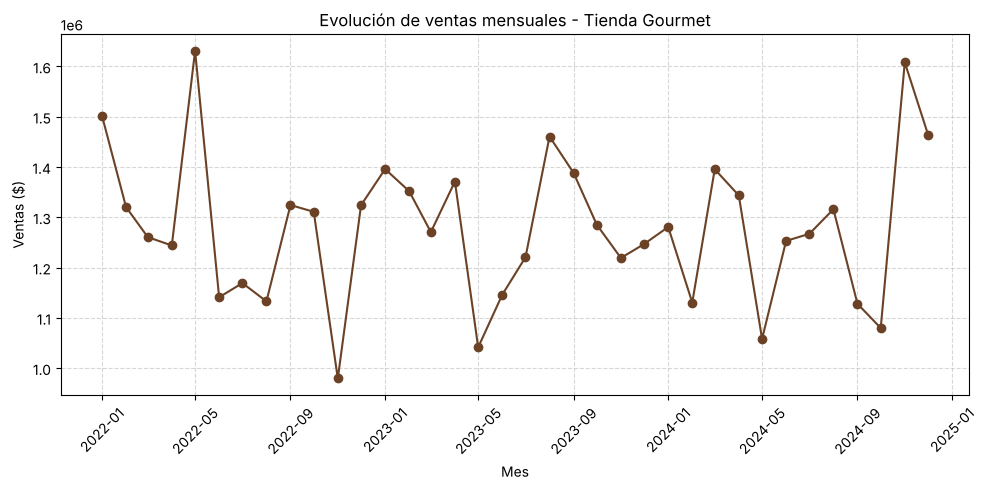

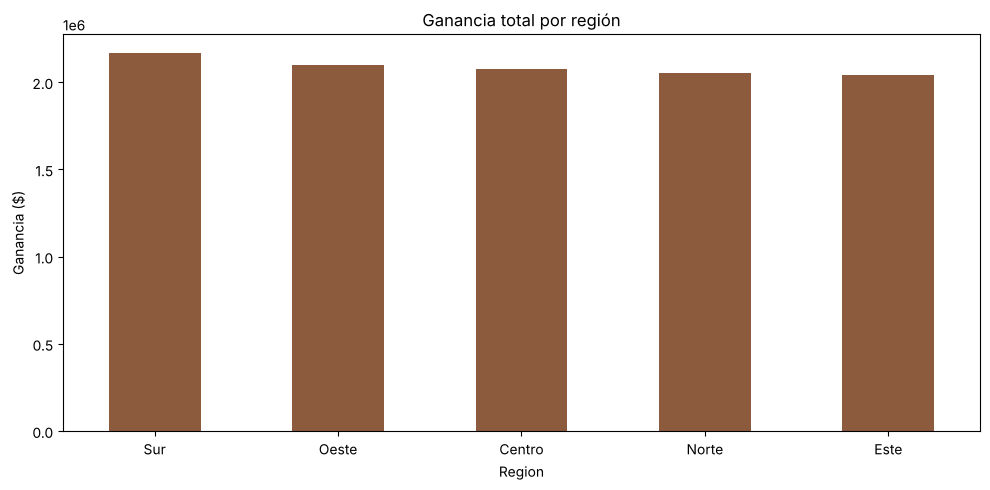

In [ ]:
serie_ventas = df.groupby('Anio_Mes')['Ventas'].sum()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(serie_ventas.index, serie_ventas.values, marker='o', color='#6b4226')
ax.set_title('Evolución de ventas mensuales - Tienda Gourmet')
ax.set_xlabel('Mes')
ax.set_ylabel('Ventas ($)')
ax.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ganancia_region = df.groupby('Region')['Ganancia'].sum().sort_values(ascending=False)
ax = ganancia_region.plot(kind='bar', color='#8c5a3c', title='Ganancia total por región')
ax.set_ylabel('Ganancia ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Pronóstico estadístico (Holt-Winters)

Suavizado exponencial con tendencia y estacionalidad anual aditiva sobre las ventas mensuales. Se evalúa con los últimos 6 meses como prueba y luego se pronostican los 6 meses siguientes.

Holt-Winters en prueba -> MAE = 243,297 | RMSE = 301,456


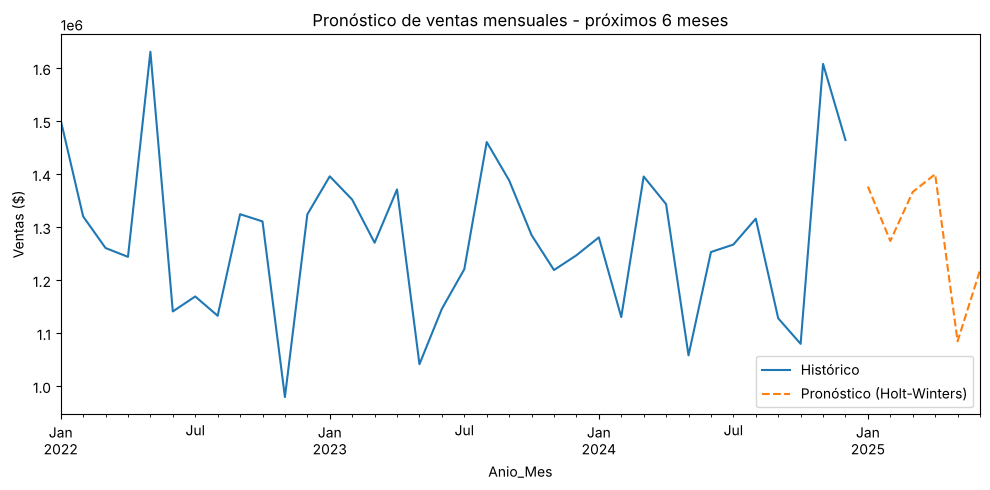

,Pronostico_Ventas
2025-01-01,1376703.03
2025-02-01,1274010.81
2025-03-01,1366531.94
2025-04-01,1399982.54
2025-05-01,1084713.56
2025-06-01,1218624.55


In [ ]:
H = 6  # horizonte en meses

serie = serie_ventas.asfreq('MS')
train, test = serie[:-H], serie[-H:]

# Evaluación con conjunto de prueba
modelo_eval = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12).fit()
pred_hw_test = modelo_eval.forecast(H)
mae_hw = mean_absolute_error(test, pred_hw_test)
rmse_hw = np.sqrt(mean_squared_error(test, pred_hw_test))
print(f'Holt-Winters en prueba -> MAE = {mae_hw:,.0f} | RMSE = {rmse_hw:,.0f}')

# Pronóstico final con toda la serie
modelo_final = ExponentialSmoothing(serie, trend='add', seasonal='add', seasonal_periods=12).fit()
pronostico = modelo_final.forecast(H)

ax = serie.plot(label='Histórico')
pronostico.plot(ax=ax, linestyle='--', label='Pronóstico (Holt-Winters)')
ax.set_title('Pronóstico de ventas mensuales - próximos 6 meses')
ax.set_ylabel('Ventas ($)')
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'Pronostico_Ventas': pronostico.round(2)})

## 6. Aprendizaje profundo (LSTM con Keras)

Red LSTM que aprende de ventanas de 6 meses consecutivos para predecir el mes siguiente. Se normaliza con estadísticas del tramo de entrenamiento y se compara con Holt-Winters en el mismo conjunto de prueba.



I0000 00:00:1793282414.012292     242 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793282414.075119     242 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793282415.234986     242 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Épocas entrenadas: 45
LSTM en prueba -> MAE = 148,062
Holt-Winters en prueba -> MAE = 243,297
Menor error: LSTM


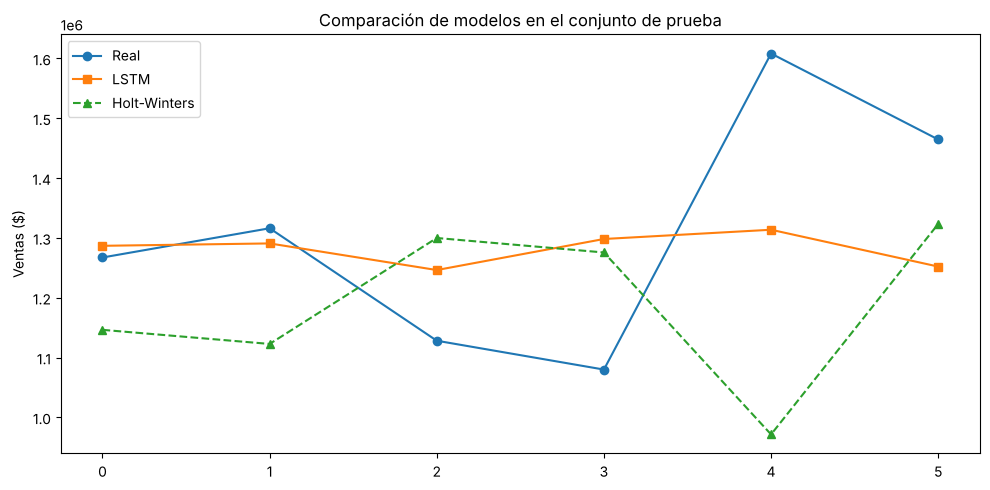

In [ ]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)

VENTANA = 6
valores = serie.values.astype('float32')
media, desvio = valores[:-H].mean(), valores[:-H].std()
normalizado = (valores - media) / desvio

X, y = [], []
for i in range(len(normalizado) - VENTANA):
    X.append(normalizado[i:i + VENTANA])
    y.append(normalizado[i + VENTANA])
X = np.array(X).reshape(-1, VENTANA, 1)
y = np.array(y)

X_train, y_train = X[:-H], y[:-H]
X_test, y_test = X[-H:], y[-H:]

modelo_dl = keras.Sequential([
    keras.layers.Input(shape=(VENTANA, 1)),
    keras.layers.LSTM(32),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1),
])
modelo_dl.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mse')

parada = keras.callbacks.EarlyStopping(patience=40, restore_best_weights=True)
historia = modelo_dl.fit(X_train, y_train, validation_split=0.2, epochs=500,
                         verbose=0, callbacks=[parada])
print('Épocas entrenadas:', len(historia.history['loss']))

pred_lstm = modelo_dl.predict(X_test, verbose=0).ravel() * desvio + media
real = y_test * desvio + media

mae_lstm = mean_absolute_error(real, pred_lstm)
print(f'LSTM en prueba -> MAE = {mae_lstm:,.0f}')
print(f'Holt-Winters en prueba -> MAE = {mae_hw:,.0f}')
print('Menor error:', 'LSTM' if mae_lstm < mae_hw else 'Holt-Winters')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(real, marker='o', label='Real')
ax.plot(pred_lstm, marker='s', label='LSTM')
ax.plot(pred_hw_test.values, marker='^', linestyle='--', label='Holt-Winters')
ax.set_title('Comparación de modelos en el conjunto de prueba')
ax.set_ylabel('Ventas ($)')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Backend para el dashboard

Se exportan los KPI, el pronóstico y las métricas de los modelos a `analisis_backend.json`. El dashboard puede leer ese archivo para mostrar los resultados del análisis junto a los gráficos existentes.

In [ ]:
payload = {
    'kpi': {
        'ventas_totales': round(float(df['Ventas'].sum()), 2),
        'ganancia_total': round(float(df['Ganancia'].sum()), 2),
        'margen_promedio_pct': round(float(df['Margen_Pct'].mean()), 2),
        'region_lider': str(ganancia_region.index[0]),
        'categoria_lider': str(resumen_cat.index[0]),
    },
    'pronostico_ventas': {
        str(fecha.date()): round(float(v), 2) for fecha, v in pronostico.items()
    },
    'metricas_modelos': {
        'mae_holt_winters': round(float(mae_hw), 2),
        'rmse_holt_winters': round(float(rmse_hw), 2),
        'mae_lstm': round(float(mae_lstm), 2),
    },
}

with open('analisis_backend.json', 'w', encoding='utf-8') as archivo:
    json.dump(payload, archivo, ensure_ascii=False, indent=2)

print(json.dumps(payload, indent=2, ensure_ascii=False))

{
  "kpi": {
    "ventas_totales": 46064550.51,
    "ganancia_total": 10442696.78,
    "margen_promedio_pct": 22.86,
    "region_lider": "Sur",
    "categoria_lider": "Vinos y Bebidas"
  },
  "pronostico_ventas": {
    "2025-01-01": 1376703.03,
    "2025-02-01": 1274010.81,
    "2025-03-01": 1366531.94,
    "2025-04-01": 1399982.54,
    "2025-05-01": 1084713.56,
    "2025-06-01": 1218624.55
  },
  "metricas_modelos": {
    "mae_holt_winters": 243296.57,
    "rmse_holt_winters": 301455.62,
    "mae_lstm": 148061.52
  }
}


## 8. Diccionario de datos (columnas del CSV y derivadas)

| Columna | Tipo | Descripción |
|---|---|---|
| `ID_Pedido` | texto | Identificador único del pedido (ej. GRM-10000) |
| `Fecha_Pedido` | datetime | Fecha en que se realizó el pedido |
| `Categoria` | texto | Rubro: Vinos y Bebidas, Quesos y Fiambres, Cafes e Infusiones, Dulces y Conservas, Aceites y Condimentos |
| `Producto` | texto | Producto vendido |
| `Region` | texto | Región: Centro, Norte, Sur, Este, Oeste |
| `Canal_Venta` | texto | Canal: Tienda Online, App Movil, Telefono |
| `Cantidad` | int | Unidades vendidas en el pedido |
| `Descuento` | float | Descuento aplicado (0 a 1) |
| `Ventas` | float | Monto facturado del pedido ($) |
| `Ganancia` | float | Ganancia neta del pedido ($). Puede ser negativa |
| `Anio`, `Mes` | int | Componentes de la fecha |
| `Anio_Mes` | datetime | Primer día del mes, para agregaciones mensuales |
| `Margen_Pct` | float | Ganancia / Ventas x 100 |